In [ ]:
# RF-DETR Medium Inference on External Test Images

Author: Salini S  
Period: August 2026  
Project: Smartphone Imaging-Based AI for Early Detection and Screening of Ocular Surface and Eyelid Tumours  
Model: RF-DETR Medium  
Task: External inference and evaluation  

This notebook loads a selected RF-DETR checkpoint and performs object detection on external eyelid images. The pipeline predicts eyelid-tumour locations, visualises bounding boxes with confidence scores, and saves the annotated images and prediction details for qualitative and quantitative evaluation.

## Model variants tested

- RF-DETR trained using annotated eyelid-tumour images
- RF-DETR trained with additional normal-image negatives
- Selected checkpoint: `checkpoint_best_total.pth` (EMA)

## Inputs

- Trained RF-DETR Medium checkpoint (`.pth`)
- Folder containing external eyelid-tumour and normal images

## Outputs

- Annotated detection images
- CSV file containing image-level predictions
- Bounding-box coordinates and confidence scores
- Visualisation of detection results

In [2]:
# Mount google drive
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [1]:
# Install packages
!pip install -q rfdetr supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.1/491.1 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.3/373.3 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.5/35.5 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 6.8 MB/s eta 0:00:00


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont

from rfdetr import RFDETRMedium

In [ ]:
# Path

CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/RF_DETR_Output_V2/checkpoint_best_total.pth"
)

TEST_IMAGE_DIR = Path(
    "/content/drive/MyDrive/Test3.0"
)

RESULT_DIR = Path(
    "/content/drive/MyDrive/RF_DETR_Test_Results_V2"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

assert TEST_IMAGE_DIR.exists(), (
    f"Test folder not found: {TEST_IMAGE_DIR}"
)

print("Checkpoint:", CHECKPOINT_PATH)
print("Test images:", TEST_IMAGE_DIR)
print("Results:", RESULT_DIR)


In [5]:
# Loading trained RF- DETR model
model = RFDETRMedium(
    pretrain_weights=str(CHECKPOINT_PATH)
)

print("RF-DETR model loaded successfully.")

[2026-08-07 06:53:44] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-07 06:53:44] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-07 06:53:50] [WARNING] rf-detr - Checkpoint has 2 classes but model is configured for 90. Using checkpoint class count (2). Pass num_classes=2 to suppress this warning.
[2026-08-07 06:53:50] [WARNING] rf-detr - load_pretrain_weights: checkpoint lacks args.num_queries / args.group_detr; falling back to flat slice. With group_detr=13 this may scramble per-group query structure if the checkpoint was trained with group_detr > 1.


RF-DETR model loaded successfully.


In [ ]:
# Testing 1 image
IMAGE_PATH = TEST_IMAGE_DIR / "Eyelid6.jpg"

assert IMAGE_PATH.exists(), f"Image not found: {IMAGE_PATH}"

image = Image.open(IMAGE_PATH).convert("RGB")

detections = model.predict(
    image,
    threshold=0.30
)

print("Number of detections:", len(detections))
print("Bounding boxes:\n", detections.xyxy)
print("Confidence scores:\n", detections.confidence)
print("Class IDs:\n", detections.class_id)

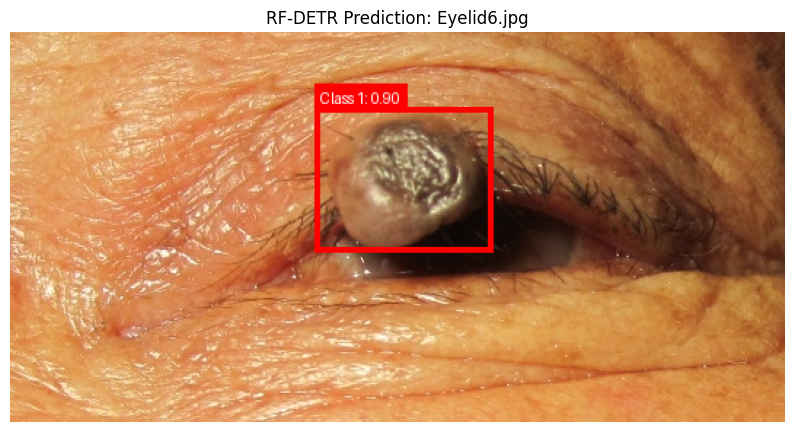

In [ ]:
# Display dtected lesion
CLASS_NAMES = {
    1: "Eyelid Tumor"
}

display_image = image.copy()
draw = ImageDraw.Draw(display_image)

for box, confidence, class_id in zip(
    detections.xyxy,
    detections.confidence,
    detections.class_id
):
    x1, y1, x2, y2 = map(int, box)

    class_id = int(class_id)
    confidence = float(confidence)

    class_name = CLASS_NAMES.get(
        class_id,
        f"Class {class_id}"
    )

    label = f"{class_name}: {confidence:.2f}"

    draw.rectangle(
        [(x1, y1), (x2, y2)],
        outline="red",
        width=4
    )

    text_box = draw.textbbox((x1, y1), label)
    text_width = text_box[2] - text_box[0]
    text_height = text_box[3] - text_box[1]

    label_y = max(0, y1 - text_height - 8)

    draw.rectangle(
        [
            (x1, label_y),
            (x1 + text_width + 8, label_y + text_height + 8)
        ],
        fill="red"
    )

    draw.text(
        (x1 + 4, label_y + 4),
        label,
        fill="white"
    )

plt.figure(figsize=(10, 8))
plt.imshow(display_image)
plt.title(f"RF-DETR Prediction: {IMAGE_PATH.name}")
plt.axis("off")
plt.show()

**Note:** RF-DETR returned foreground class ID `1` for eyelid-tumour detections. The saved output displays `Class 1` because the class-name mapping was corrected after this run. Here, `Class 1` corresponds to **Eyelid Tumour**.

In [8]:
# Testing entire external dataset
import pandas as pd

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

image_paths = sorted(
    path for path in TEST_IMAGE_DIR.iterdir()
    if path.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Found {len(image_paths)} test images.")

Found 32 test images.


In [9]:
CONFIDENCE_THRESHOLD = 0.30

prediction_records = []

for image_path in image_paths:

    try:
        image = Image.open(image_path).convert("RGB")
        annotated_image = image.copy()
        draw = ImageDraw.Draw(annotated_image)

        detections = model.predict(
            image,
            threshold=CONFIDENCE_THRESHOLD
        )

        if len(detections) == 0:
            prediction_records.append({
                "image_name": image_path.name,
                "detection_number": 0,
                "predicted_class": "No detection",
                "confidence": 0.0,
                "x1": None,
                "y1": None,
                "x2": None,
                "y2": None
            })

        else:
            for detection_number, (
                box,
                confidence,
                class_id
            ) in enumerate(
                zip(
                    detections.xyxy,
                    detections.confidence,
                    detections.class_id
                ),
                start=1
            ):

                x1, y1, x2, y2 = map(int, box)
                confidence = float(confidence)
                class_id = int(class_id)

                class_name = CLASS_NAMES.get(
                    class_id,
                    f"Class {class_id}"
                )

                label = f"{class_name}: {confidence:.2f}"

                draw.rectangle(
                    [(x1, y1), (x2, y2)],
                    outline="red",
                    width=4
                )

                text_box = draw.textbbox(
                    (x1, y1),
                    label
                )

                text_width = text_box[2] - text_box[0]
                text_height = text_box[3] - text_box[1]

                label_y = max(
                    0,
                    y1 - text_height - 8
                )

                draw.rectangle(
                    [
                        (x1, label_y),
                        (
                            x1 + text_width + 8,
                            label_y + text_height + 8
                        )
                    ],
                    fill="red"
                )

                draw.text(
                    (x1 + 4, label_y + 4),
                    label,
                    fill="white"
                )

                prediction_records.append({
                    "image_name": image_path.name,
                    "detection_number": detection_number,
                    "predicted_class": class_name,
                    "confidence": confidence,
                    "x1": x1,
                    "y1": y1,
                    "x2": x2,
                    "y2": y2
                })

        output_path = RESULT_DIR / image_path.name

        # JPEG does not support transparency, but RGB conversion above
        # ensures consistent saving.
        annotated_image.save(output_path)

        print(
            f"{image_path.name}: "
            f"{len(detections)} detection(s)"
        )

    except Exception as error:
        print(f"Failed on {image_path.name}: {error}")

        prediction_records.append({
            "image_name": image_path.name,
            "detection_number": None,
            "predicted_class": "Processing error",
            "confidence": None,
            "x1": None,
            "y1": None,
            "x2": None,
            "y2": None
        })

Eyelid1.JPG: 1 detection(s)
Eyelid10.jpg: 1 detection(s)
Eyelid11.jpg: 1 detection(s)
Eyelid12.jpg: 2 detection(s)
Eyelid13.JPG: 1 detection(s)
Eyelid14.JPG: 1 detection(s)
Eyelid15.JPG: 1 detection(s)
Eyelid16.jpg: 1 detection(s)
Eyelid17.jpg: 2 detection(s)
Eyelid18.jpg: 1 detection(s)
Eyelid19.jpg: 1 detection(s)
Eyelid2.jpg: 1 detection(s)
Eyelid20.jpg: 1 detection(s)
Eyelid21.jpg: 1 detection(s)
Eyelid22.jpg: 1 detection(s)
Eyelid23.jpg: 1 detection(s)
Eyelid3.jpg: 1 detection(s)
Eyelid4.jpg: 1 detection(s)
Eyelid5.jpg: 1 detection(s)
Eyelid6.jpg: 1 detection(s)
Eyelid7.jpg: 1 detection(s)
Eyelid8.jpg: 1 detection(s)
Eyelid9.jpg: 1 detection(s)
Normal11.jpg: 1 detection(s)
Normal12.png: 0 detection(s)
Normal2.jpeg: 0 detection(s)
Normal3.jpg: 0 detection(s)
Normal5.jpeg: 1 detection(s)
Normal6.jpg: 0 detection(s)
Normal7.jpeg: 0 detection(s)
Normal8.jpg: 0 detection(s)
Normal9.jpeg: 0 detection(s)


In [10]:
# Save predictions to csv
predictions_df = pd.DataFrame(prediction_records)

CSV_PATH = RESULT_DIR / "rf_detr_test_predictions.csv"

predictions_df.to_csv(
    CSV_PATH,
    index=False
)

print("Prediction CSV saved to:")
print(CSV_PATH)

predictions_df.head(32)

Prediction CSV saved to:
/content/drive/MyDrive/RF_DETR_Test_Results_V2/rf_detr_test_predictions.csv


,image_name,detection_number,predicted_class,confidence,x1,y1,x2,y2
0,Eyelid1.JPG,1,Class 1,0.873205,374.0,314.0,540.0,452.0
1,Eyelid10.jpg,1,Class 1,0.838456,224.0,64.0,367.0,173.0
2,Eyelid11.jpg,1,Class 1,0.731476,58.0,101.0,731.0,494.0
3,Eyelid12.jpg,1,Class 1,0.479176,1130.0,727.0,1617.0,1292.0
4,Eyelid12.jpg,2,Class 1,0.324549,1039.0,731.0,1670.0,1508.0
5,Eyelid13.JPG,1,Class 1,0.825281,535.0,364.0,757.0,507.0
6,Eyelid14.JPG,1,Class 1,0.835175,515.0,91.0,786.0,329.0
7,Eyelid15.JPG,1,Class 1,0.789576,277.0,353.0,545.0,518.0
8,Eyelid16.jpg,1,Class 1,0.788091,112.0,134.0,232.0,207.0
9,Eyelid17.jpg,1,Class 1,0.652989,0.0,331.0,220.0,795.0


In [11]:
# Display test result
result_images = sorted(
    path for path in RESULT_DIR.iterdir()
    if path.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Displaying {len(result_images)} images...")

for result_path in result_images:

    result_image = Image.open(result_path).convert("RGB")

    plt.figure(figsize=(8, 6))
    plt.imshow(result_image)
    plt.title(result_path.name)
    plt.axis("off")
    plt.show()

Output hidden; open in https://colab.research.google.com to view.